# Завантаження бібліотеки ray та налаштування середовища

In [ ]:
!pip install -q "ray[default]"

In [ ]:
import os, time
import numpy as np
import pandas as pd
import ray

Робота буде виконуватись із використанням **датасету транзакцій Online Retail**, який містить історичні дані про продажі інтернет-магазину. Він включає інформацію про номер рахунку, товар, кількість проданих одиниць, дату операції, ціну, ідентифікатор покупця та країну. На основі цих даних формується щоденна виручка, яка використовується для розподіленої обробки, побудови ознак та прогнозування майбутніх продажів. Датасет дає змогу продемонструвати роботу моделей Task, Actor, Agent та Multi-Agent на реальних транзакційних даних.


# Завантаження та препроцесинг датасету

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATA_PATH = "/content/drive/MyDrive/data/online_retail.csv"

df = pd.read_csv(DATA_PATH, encoding="latin1")

print("Shape:", df.shape)
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:

def clean_online_retail(df):
    df = df.copy()
    df = df.replace(["", " ", "NULL", "null", "None", "none", "N/A", "n/a", "NA", "na"], np.nan)
    df = df.dropna(how="all")
    df = df.drop_duplicates()
    df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
    df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
    df = df.dropna(subset=["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate"])
    df = df[df["Quantity"] > 0]
    df = df[df["UnitPrice"] > 0]
    df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
    df = df.reset_index(drop=True)
    return df

In [ ]:
clean_dataframe = clean_online_retail(df)
print("Shape:", clean_dataframe.shape)
display(clean_dataframe.head())


Shape: (524878, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


# 1. Дослідити організацію виконання розподілених обчислень на основі моделі Task.


**Опис моделі та її механізми**


Модель Task (функціональна модель / model of tasks) базується на виконанні бездержавних (stateless) функцій у розподіленому середовищі. У цій моделі завдання є атомарною одиницею обчислень: ви передаєте функцію та вхідні дані на виконання на будь-який доступний вузол кластера. Головна особливість — завдання є паралельними, а їх результати повертаються у вигляді асинхронних посилань (futures), що дозволяє ефективно керувати залежностями без блокування основного потоку.

**Основні сутності та механізми, що забезпечують роботу моделі Task, включають:**

Task Function (Віддалена функція): базова функція користувача, яка містить логіку обчислень і може викликатися віддалено.

ObjectRef (Посилання на об'єкт / Future): спеціальний дескриптор, який миттєво повертається при виклику задачі ще до завершення її обчислень. Він слугує асинхронним посиланням на майбутній результат.

Distributed Object Store (Розподілене сховище об'єктів): внутрішній механізм зберігання даних у пам'яті (наприклад, Apache Arrow Plasma в Ray), де зберігаються результати виконання задач і звідки вони прозоро читаються іншими задачами.

Механізм передачі посилань (Pass-by-reference) та лінивого виконання: передача великих об'єктів у задачі здійснюється через їх ідентифікатори у сховищі, що мінімізує дублювання трафіку, а блокуюча операція отримання результату (ray.get()) зупиняє подальший хід лише тоді, коли дані реально необхідні.


**Реалізація в Ray**

У фреймворку Ray ця модель реалізується дуже просто за допомогою декоратора @ray.remote, який застосовується до звичайної Python-функції. Шляхом виклику функції через метод .remote() (func.remote(arg)) створюється віддалена задача, а повернений об'єкт ObjectRef дозволяє асинхронно контролювати її стан.




Окрім **Ray**, подібний підхід до організації паралельних і розподілених обчислень використовують:

* **Dask** — розподіляє окремі задачі між доступними ресурсами;
* **Apache Spark** — забезпечує паралельну обробку великих даних через RDD та DataFrame;
* **Celery** — виконує задачі розподілено через черги повідомлень;
* **`concurrent.futures` та `multiprocessing`** — забезпечують паралельне виконання на одному комп’ютері;
* **OpenMP, Intel TBB, Cilk** — реалізують задачний паралелізм у C/C++.

**Спільна ідея:** складне обчислення поділяється на окремі задачі, які можуть виконуватися паралельно або розподілятися між ресурсами.


# Запропонована Задача

Для практичної демонстрації та перевірки роботи моделі Task було обрано реальний і масштабний набір даних — UCI Online Retail dataset. Головною метою експерименту є паралельне обчислення агрегованої статистики (наприклад, загальної суми продажу, мінімальної ціни замовлення тощо) шляхом розділення всього масиву даних на окремі блоки та їх незалежної обробки розподіленими задачами.

In [ ]:
import time

def analyze_data(df):
    start_time = time.perf_counter()

    result = {
        "quantity_sum": df["Quantity"].sum(),
        "revenue_sum": df["TotalPrice"].sum(),
        "price_min": df["UnitPrice"].min(),
        "price_max": df["UnitPrice"].max(),
        "unique_countries": df["Country"].nunique()
    }

    result["execution_time"] = time.perf_counter() - start_time

    return result

In [ ]:
def print_results(results, title="RESULTS"):
    print(f"{title}")
    print("=" * 50)

    for key, value in results.items():
        print(f"{key:<30} {value}")

    print("=" * 50)

In [ ]:
sequential_result = analyze_data(clean_dataframe)
print_results(sequential_result,title="RESULTS")

RESULTS
quantity_sum                   5572420
revenue_sum                    10642110.804
price_min                      0.001
price_max                      13541.33
unique_countries               38
execution_time                 0.1149141169989889


In [ ]:
@ray.remote
def analyze_block(df):
    return {
        "quantity_sum": df["Quantity"].sum(),
        "revenue_sum": df["TotalPrice"].sum(),
        "row_count": len(df),
        "price_min": df["UnitPrice"].min(),
        "price_max": df["UnitPrice"].max(),
        "countries": set(df["Country"].dropna().unique())
    }

def split_data(df, num_tasks=4):
    return np.array_split(df, num_tasks)

def run_tasks(blocks):
    tasks = [analyze_block.remote(block) for block in blocks]
    return ray.get(tasks)

def aggregate_results(results):
    total_quantity = sum(result["quantity_sum"] for result in results)
    total_revenue = sum(result["revenue_sum"] for result in results)
    total_rows = sum(result["row_count"] for result in results)
    min_price = min(result["price_min"] for result in results)
    max_price = max(result["price_max"] for result in results)
    countries = set().union(*(result["countries"] for result in results))

    return {
        "quantity_sum": total_quantity,
        "revenue_sum": total_revenue,
        "avg_quantity": total_quantity / total_rows,
        "min_price": min_price,
        "max_price": max_price,
        "unique_countries": len(countries)
    }

def run_ray_analysis(df, num_tasks=4, num_cpus=4):
    blocks = split_data(df, num_tasks)
    start_time = time.perf_counter()
    results = run_tasks(blocks)
    execution_time = time.perf_counter() - start_time
    result = aggregate_results(results)
    result["execution_time"] = execution_time
    return result


# Створення драйвера ray

In [ ]:
def init_ray(num_cpus=4):
    ray.shutdown()
    return ray.init(num_cpus=num_cpus)

In [ ]:
ray.shutdown()
ray.init(num_cpus=4)

2026-09-30 08:30:32,260	INFO worker.py:2015 -- Started a local Ray instance. View the dashboard at http://127.0.0.1:8265 


Python version:,3.13.15
Ray version:,2.58.0
Dashboard:,http://127.0.0.1:8265


In [ ]:
ray_result = run_ray_analysis(clean_dataframe, num_tasks=4, num_cpus=4)
print_results(ray_result)

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


RESULTS
quantity_sum                   5572420
revenue_sum                    10642110.804
avg_quantity                   10.616600429052085
min_price                      0.001
max_price                      13541.33
unique_countries               38
execution_time                 14.056406577999951


Порівняння результатів показує, що обидва підходи (послідовний та розподілений на основі моделі Task у Ray) забезпечують абсолютно ідентичні математичні показники загальної кількості товарів (5572420) та доходу (10642110.804), що підтверджує коректність розбиття даних. Водночас за часом виконання послідовний варіант виявився суттєво швидшим, тоді як виконання через Ray Tasks зайняло значно більше часу. Така різниця зумовлена накладними витратами на ініціалізацію розподіленого середовища, серіалізацію та комунікацію даних між воркерами, які для даного обсягу даних перевищують вигоду від паралелізації.

Проведення екмперементів із різною кількістю Task

In [ ]:
def run_experiment(df, task_counts=(2, 4, 8), repetitions=5):
    experiment_results = []
    sequential_times = []
    for _ in range(repetitions):
        result = analyze_data(df)
        sequential_times.append(result["execution_time"])
    sequential_mean = np.mean(sequential_times)
    experiment_results.append({"Method": "Sequential", "Tasks": 1, "Mean time, s": sequential_mean, "Min time, s": np.min(sequential_times), "Max time, s": np.max(sequential_times), "Speedup": 1.0})
    for num_tasks in task_counts:
        ray_times = []
        for _ in range(repetitions):
            result = run_ray_analysis(df, num_tasks=num_tasks, num_cpus=num_tasks)
            ray_times.append(result["execution_time"])
        ray_mean = np.mean(ray_times)
        experiment_results.append({"Method": "Ray", "Tasks": num_tasks, "Mean time, s": ray_mean, "Min time, s": np.min(ray_times), "Max time, s": np.max(ray_times), "Speedup": sequential_mean / ray_mean})
    return pd.DataFrame(experiment_results)

results_table = run_experiment(clean_dataframe, task_counts=(2, 4, 8), repetitions=5)
display(results_table)

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


,Method,Tasks,"Mean time, s","Min time, s","Max time, s",Speedup
0,Sequential,1,0.040448,0.034643,0.057724,1.000000
1,Ray,2,2.187205,0.284453,9.445621,0.018493
2,Ray,4,0.290604,0.268344,0.340901,0.139186
3,Ray,8,0.311183,0.289197,0.333849,0.129981


Аналіз результатів показує, що зі збільшенням кількості тасків (від Ray 2 до Ray 8) загальний час виконання суттєво зменшується (з 2.18 сек до 0.29 сек), а прискорення (Speedup) зростає. Водночас базовий послідовний підхід (Sequential) залишається найшвидшим через відсутність накладних витрат на ініціалізацію кластера, серіалізацію та міжпроцесну комунікацію в Ray.

In [ ]:
ray.shutdown()

Додатково. Переглянути результати виконання Tasks у Ray Dashboard.

У розділі Task Table можна переглянути стан кожного Task, тривалість його виконання, Node ID, Worker ID та тип задачі.

В поточному Job було виконано 4 Tasks analyze_blokcs, усі вони мали стан FINISHED. Тривалість окремих Tasks відрізнялася, а за значеннями Worker ID видно, що Ray розподіляв їх виконання між різними Worker-процесами.

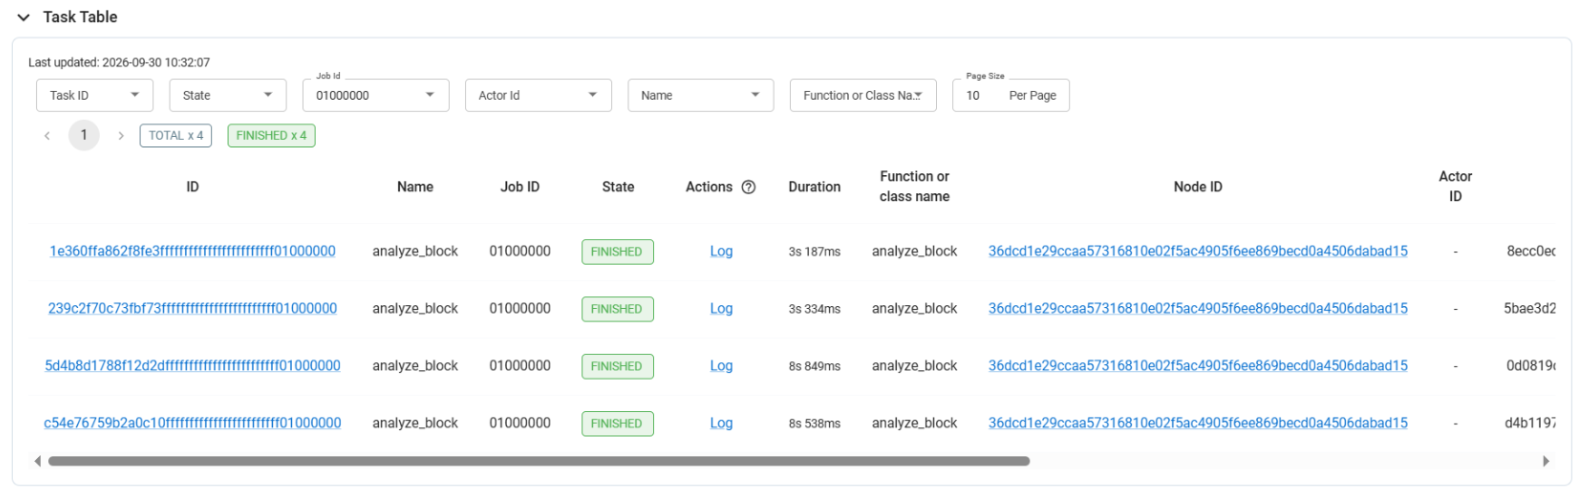

Для часового аналізу розподілу Tasks ми завантажили файл Task Timeline та відкрили його у Perfetto. Як можемо побачити, окремі таски виконуються асинхронно та займають різні проміжки часу.

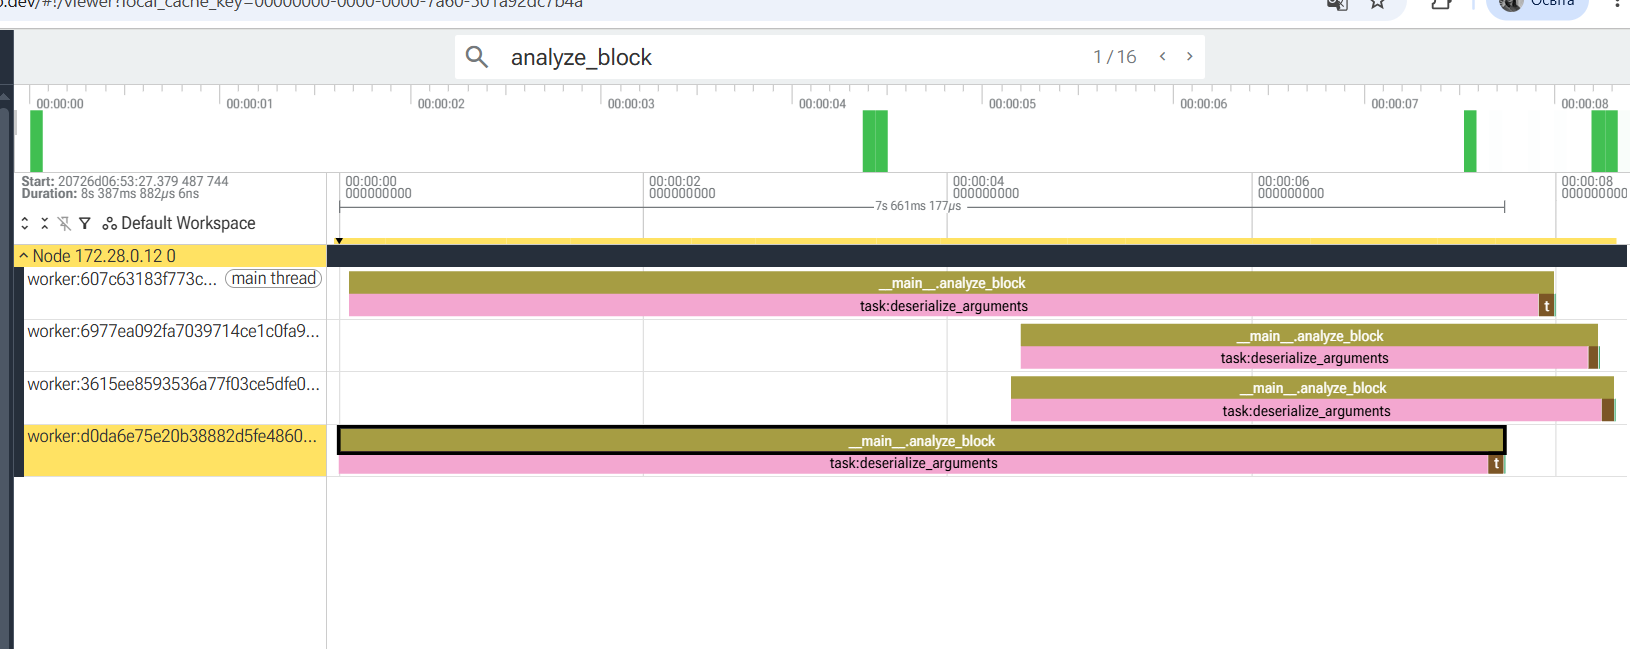

Як бачимо вузол функціонує зі стабільним низьким завантаженням. При цьому система задіює **4 воркери** та 1 актор, споживаючи близько 8.4% ресурсів центрального процесора. Обсяги зайнятої пам'яті (355.71 MB із 12.67 GB) та дискового простору залишаються на мінімальному рівні, що свідчить про комфортний запас доступних обчислювальних ресурсів кластера.

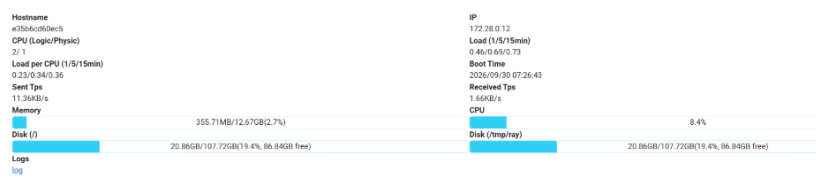

# 2. Дослідити організацію розподілених обчислень на основі моделі Actor.

**Опис моделі та її особливості**
Модель Actor (акторів) розширює концепцію задач тим, що додає управління станом (stateful model). Якщо в модель Task задачі є бездержавними (stateless) і виконуються ізольовано, то актор є довгоживучим об'єктом, який інкапсулює внутрішній стан і набір методів для його модифікації або зчитування. Взаємодія з актором відбувається виключно через асинхронну відправку повідомлень (викликів методів), що забезпечує потокобезпеку (thread safety) і природне управління станом у розподіленому середовищі без необхідності ручного налаштування блокувань (locks).

### Сутності

**Actor class** (`@ray.remote class`) — клас, на основі якого створюються Actor. **Actor** — довгоживучий екземпляр класу, який має власний стан і зберігає його між викликами методів. **ActorHandle** — посилання на Actor, через яке здійснюється взаємодія з ним та викликаються його методи. **Actor task** — окремий виклик методу Actor, який може виконуватися асинхронно.

### Механізми

Виклик методів Actor здійснюється асинхронно за допомогою `handle.method.remote()`, що повертає **ObjectRef** для отримання результату. Основною особливістю Actor є **збереження стану між викликами**, завдяки чому він може підтримувати дані протягом тривалого виконання. Звичайний однопотоковий Actor обробляє виклики послідовно, а для конкурентного виконання можна використовувати `max_concurrency` або методи `async def`. Необхідні обчислювальні ресурси задаються через `num_cpus` та `num_gpus`.


Реалізація Actor у Ray

In [ ]:
@ray.remote
class Counter:
    def __init__(self):
        self.value = 0

    def increment(self):
        self.value += 1
        return self.value

    def get_value(self):
        return self.value

counter = Counter.remote()

result1 = ray.get(counter.increment.remote())
result2 = ray.get(counter.increment.remote())

print(result1)  # 1
print(result2)  # 2

Клас Counter позначається декоратором @ray.remote, що перетворює його на Actor. Об'єкт створюється через Counter.remote(), після чого counter є ActorHandle, через який можна викликати його методи. Змінна self.value зберігає свій стан між викликами: після першого increment() вона дорівнює 1, а після другого — 2. Виклик .remote() запускає метод асинхронно, а ray.get() отримує його результат.

**Інші засоби реалізації**

Подібну модель реалізують Akka та Erlang/OTP, де основою є незалежні виконавці, які взаємодіють через повідомлення. Для C++ існує CAF (C++ Actor Framework), а HPX підтримує подібні механізми для високопродуктивних розподілених обчислень. Dask і Celery також дозволяють організовувати довготривалі та розподілені задачі, хоча використовують іншу модель взаємодії.

# Реалізація власної задачі

У цій задачі потрібно розподілено обробляти великі набори даних про продажі, розділені на окремі пакети (batch). Для цього створюються окремі Actor, кожен з яких відповідає за обробку своєї частини даних і зберігає проміжні результати у власному стані. Під час обробки Actor підраховує кількість записів, загальну кількість проданих товарів, виручку, кількість унікальних товарів і країн. Після обробки всіх пакетів можна отримати загальну статистику кожного Actor, а за потреби — скинути накопичені результати.

In [ ]:
ray.shutdown()
ray.init(num_cpus=4)

2026-09-30 11:01:02,817	INFO worker.py:2015 -- Started a local Ray instance. View the dashboard at http://127.0.0.1:8265 


Python version:,3.13.15
Ray version:,2.58.0
Dashboard:,http://127.0.0.1:8265


In [ ]:
@ray.remote
class SalesAggregator:
    def __init__(self, actor_id):
        self.actor_id = actor_id
        self.total_rows = 0
        self.total_quantity = 0
        self.total_revenue = 0
        self.unique_products = set()
        self.unique_countries = set()
        self.batches_processed = 0

    def process_batch(self, df):
        self.total_rows += len(df)
        self.total_quantity += df["Quantity"].sum()
        self.total_revenue += df["TotalPrice"].sum()
        self.unique_products.update(df["StockCode"].dropna().unique())
        self.unique_countries.update(df["Country"].dropna().unique())
        self.batches_processed += 1
        time.sleep(0.2)
        return {"actor": self.actor_id, "batch": self.batches_processed, "rows": self.total_rows, "revenue": self.total_revenue}

    def get_statistics(self):
        return {"actor": self.actor_id, "batches_processed": self.batches_processed, "rows": self.total_rows, "quantity": self.total_quantity, "revenue": self.total_revenue, "unique_products": len(self.unique_products), "unique_countries": len(self.unique_countries)}

    def reset(self):
        self.total_rows = 0
        self.total_quantity = 0
        self.total_revenue = 0
        self.unique_products = set()
        self.unique_countries = set()
        self.batches_processed = 0
        return self.actor_id

In [ ]:
actors = [SalesAggregator.remote(i + 1) for i in range(4)]

Функція split_data розділяє очищений набір даних на **4 блоки**, після чого create_batches додатково ділить кожен блок на **3 пакети** для поступової обробки. Функція process_batch передає відповідний пакет кожному Actor через process_batch.remote(), після чого ray.get(refs) очікує завершення всіх паралельних обчислень і повертає їх результати.


In [ ]:
blocks = split_data(clean_dataframe, num_tasks=4)
def create_batches(blocks, num_batches=3):
    return [np.array_split(block, num_batches) for block in blocks]
def process_batch(actors, batches, batch_index):
    refs = [actors[i].process_batch.remote(batches[i][batch_index]) for i in range(len(actors))]
    return ray.get(refs)

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [ ]:
batches = create_batches(blocks, num_batches=3)
results = process_batch(actors, batches, 0)

In [ ]:
for result in results:
    print(f"Actor {result['actor']}:")
    print(f"  Batch:   {result['batch']}")
    print(f"  Rows:    {result['rows']:}")
    print(f"  Revenue: {result['revenue']:}")
    print()

Actor 1:
  Batch:   1
  Rows:    43740
  Revenue: 869646.2200000001

Actor 2:
  Batch:   1
  Rows:    43740
  Revenue: 853217.3409999999

Actor 3:
  Batch:   1
  Rows:    43740
  Revenue: 991032.6510000001

Actor 4:
  Batch:   1
  Rows:    43740
  Revenue: 892766.05



Після обробки першого батча кожен із 4 Actor опрацював по 43 740 рядків даних.

На цьому етапі отримуємо підсумкову статистику з усіх Actor після обробки даних. Для кожного Actor виводяться кількість оброблених батчів і рядків, загальна кількість товарів, виручка, а також кількість унікальних товарів і країн. Це дозволяє порівняти результати роботи всіх Actor та оцінити підсумки розподіленої обробки.


In [ ]:
def get_actor_statistics(actors):
    return ray.get([actor.get_statistics.remote() for actor in actors])

statistics = get_actor_statistics(actors)

def print_actor_statistics(statistics):
    print(f"{'Actor':<8}{'Batches':<10}{'Rows':<12}{'Quantity':<15}{'Revenue':<15}{'Products':<12}{'Countries':<12}")
    print("-" * 84)
    for stat in statistics:
        print(f"{stat['actor']:<8}{stat['batches_processed']:<10}{stat['rows']:<12,}{stat['quantity']:<15,.0f}{stat['revenue']:<15,.2f}{stat['unique_products']:<12}{stat['unique_countries']:<12}")

In [ ]:
statistics = get_actor_statistics(actors)
print_actor_statistics(statistics)

Actor   Batches   Rows        Quantity       Revenue        Products    Countries   
------------------------------------------------------------------------------------
1       1         43,740      386,264        869,646.22     2817        23          
2       1         43,740      471,961        853,217.34     2678        27          
3       1         43,740      565,460        991,032.65     2698        26          
4       1         43,740      467,030        892,766.05     2754        22          


Бачимо, що статистика виведена коректно: кожен із 4 Actor обробив по 43 740 рядків і по одному батчу, при цьому для кожного окремо розраховано кількість товарів, виручку, унікальні продукти та країни.

Далі переглядаємо в Ray Dashboard створені Actors, їх стан та виконання викликів методів.


Після проходження одного батча можна побачити, що створено 4 актори, кожен з яких має статус ALIVE

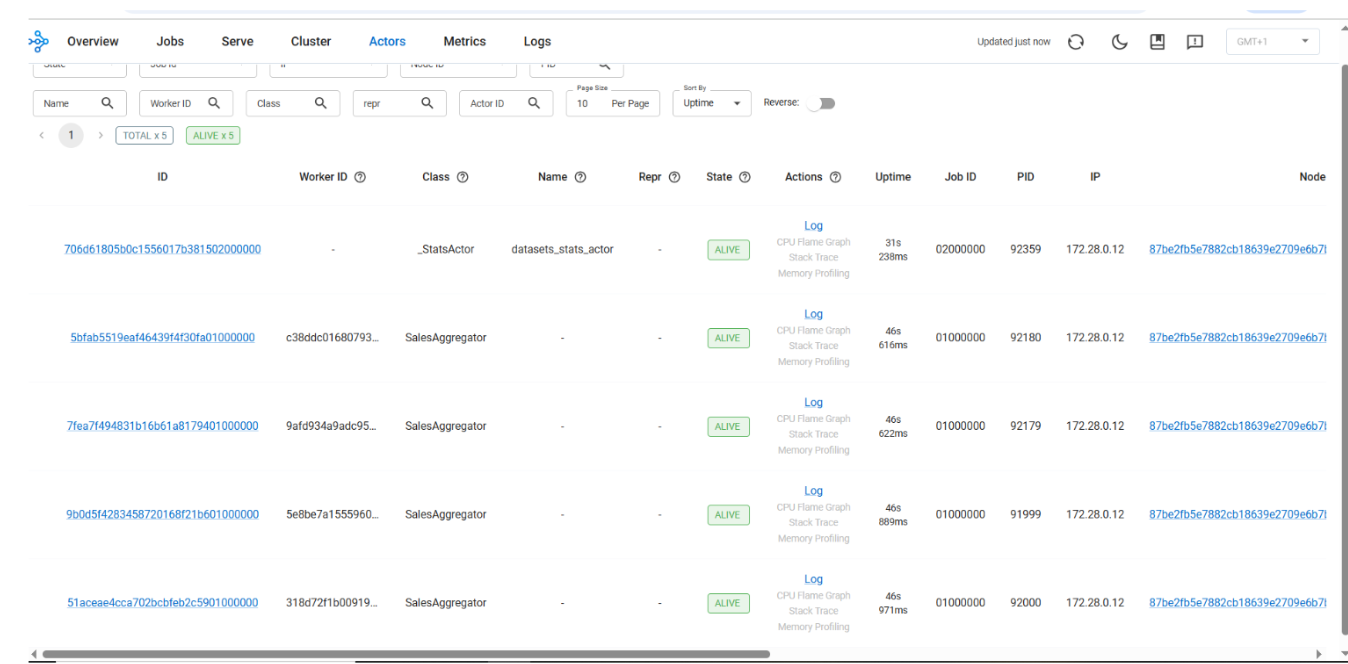

У вкладці Task можна спостерігати основні завдання, що виконувались кожним актором, серед яких основним є process_batch

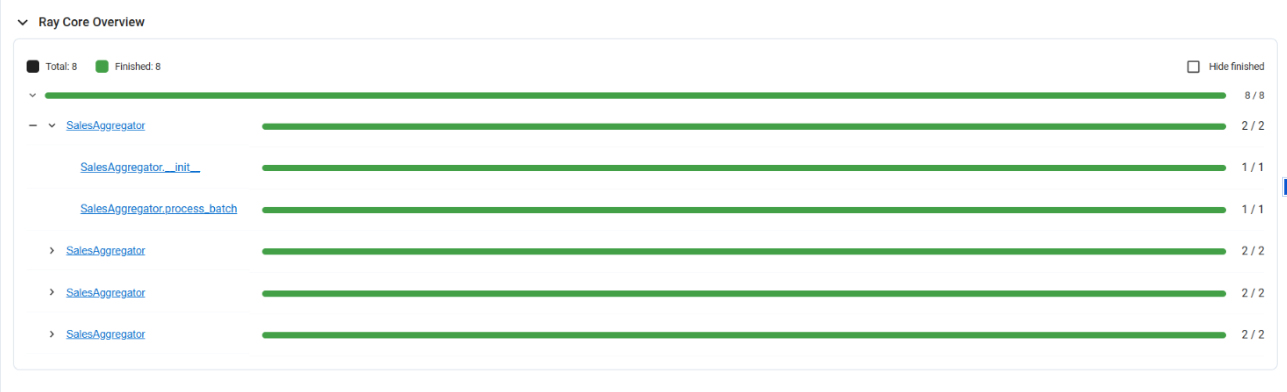

У моделі Actor задача Task представлена як Actor Task — виклик певного методу конкретного Actor. Вона виконується в контексті цього Actor і може використовувати та змінювати його збережений внутрішній стан.


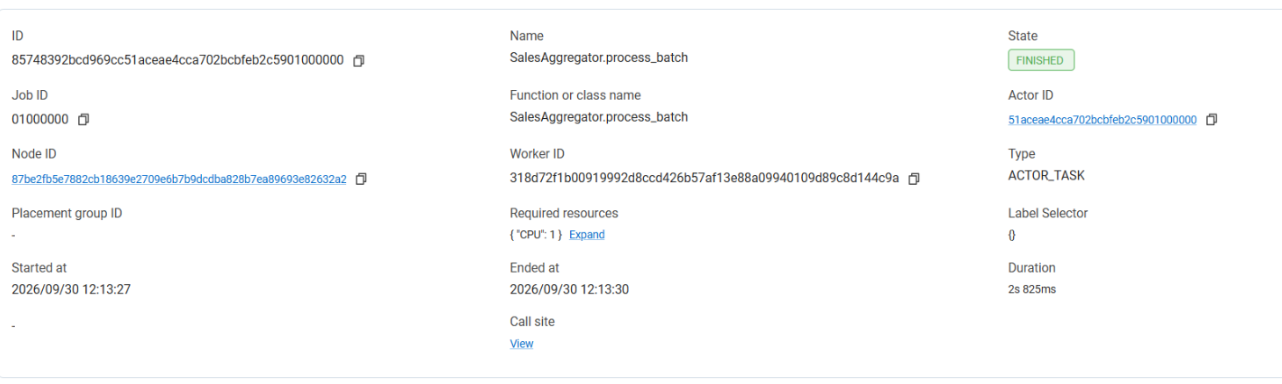

Додамо виконання ще одного батча

In [ ]:
results_1 = process_batch(actors, batches, 1)
statistics = get_actor_statistics(actors)

In [ ]:
for result in results_1:
    print(f"Actor {result['actor']}:")
    print(f"  Batch:   {result['batch']}")
    print(f"  Rows:    {result['rows']:}")
    print(f"  Revenue: {result['revenue']:}")
    print()

Actor 1:
  Batch:   2
  Rows:    87480
  Revenue: 1771339.0500000003

Actor 2:
  Batch:   2
  Rows:    87480
  Revenue: 1822776.2509999997

Actor 3:
  Batch:   2
  Rows:    87480
  Revenue: 1923856.432

Actor 4:
  Batch:   2
  Rows:    87480
  Revenue: 1682288.36



In [ ]:
print_actor_statistics(statistics)

Actor   Batches   Rows        Quantity       Revenue        Products    Countries   
------------------------------------------------------------------------------------
1       2         87,480      881,261        1,771,339.05   3026        29          
2       2         87,480      945,589        1,822,776.25   3018        31          
3       2         87,480      1,056,274      1,923,856.43   2991        28          
4       2         87,480      868,131        1,682,288.36   2996        25          


Після обробки двох батчів даних кожен із чотирьох Actor опрацював по 87 480 рядків. Накопичена статистика показує зростання кількості проданих товарів і загальної виручки порівняно з першим батчем, що підтверджує збереження стану Actor між послідовними викликами.


Далі переглянемо Ray Dashboard


Після обробки наступного батчу до кожного Actor додається нова задача, а результати обробки накопичуються в його внутрішньому стані. Це дозволяє зберігати та оновлювати загальну статистику між послідовними викликами.


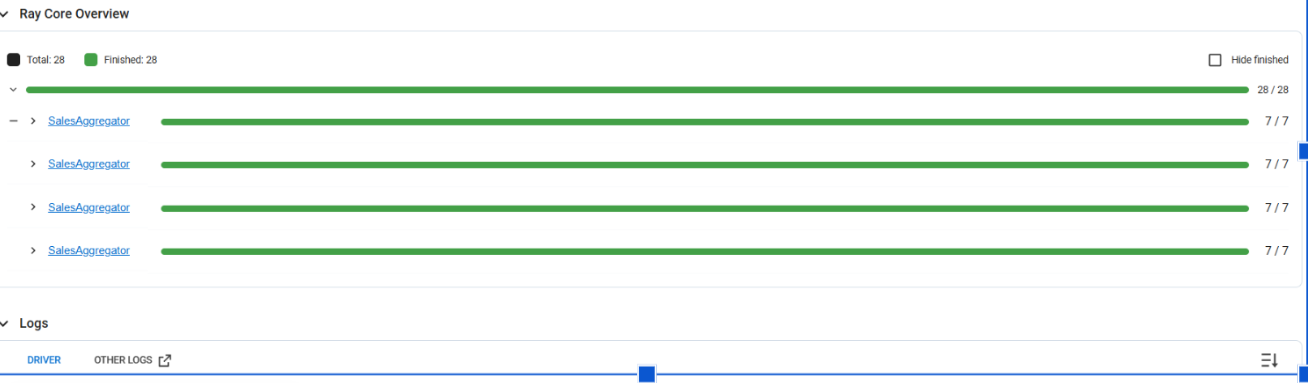

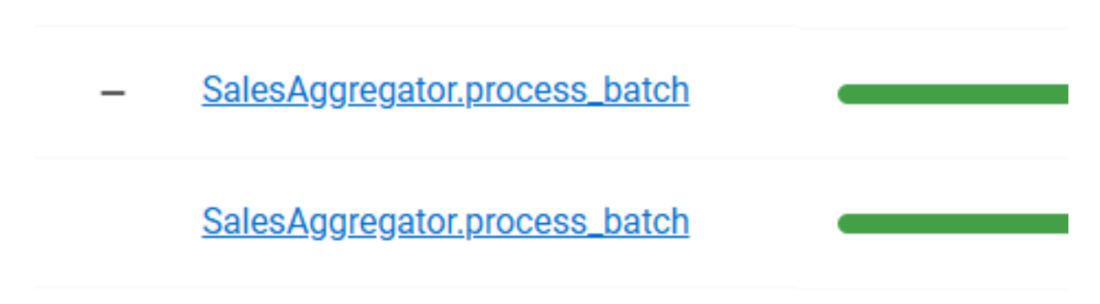

Детальніша інформація про Tasks для певного актора

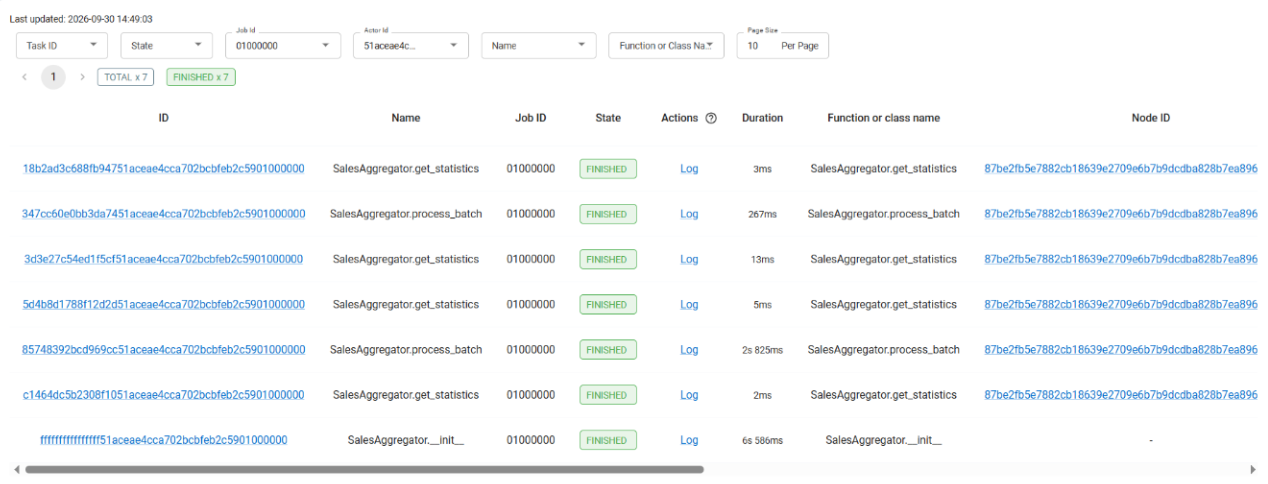

Пройдемо останній батч

In [ ]:
results_2 = process_batch(actors, batches, 2)
statistics = get_actor_statistics(actors)

In [ ]:
for result in results_2:
    print(f"Actor {result['actor']}:")
    print(f"  Batch:   {result['batch']}")
    print(f"  Rows:    {result['rows']:}")
    print(f"  Revenue: {result['revenue']:}")
    print()

Actor 1:
  Batch:   3
  Rows:    131220
  Revenue: 2597391.8100000005

Actor 2:
  Batch:   3
  Rows:    131220
  Revenue: 2646570.2009999994

Actor 3:
  Batch:   3
  Rows:    131219
  Revenue: 2777777.443

Actor 4:
  Batch:   3
  Rows:    131219
  Revenue: 2620371.35



Отриманий трейс:

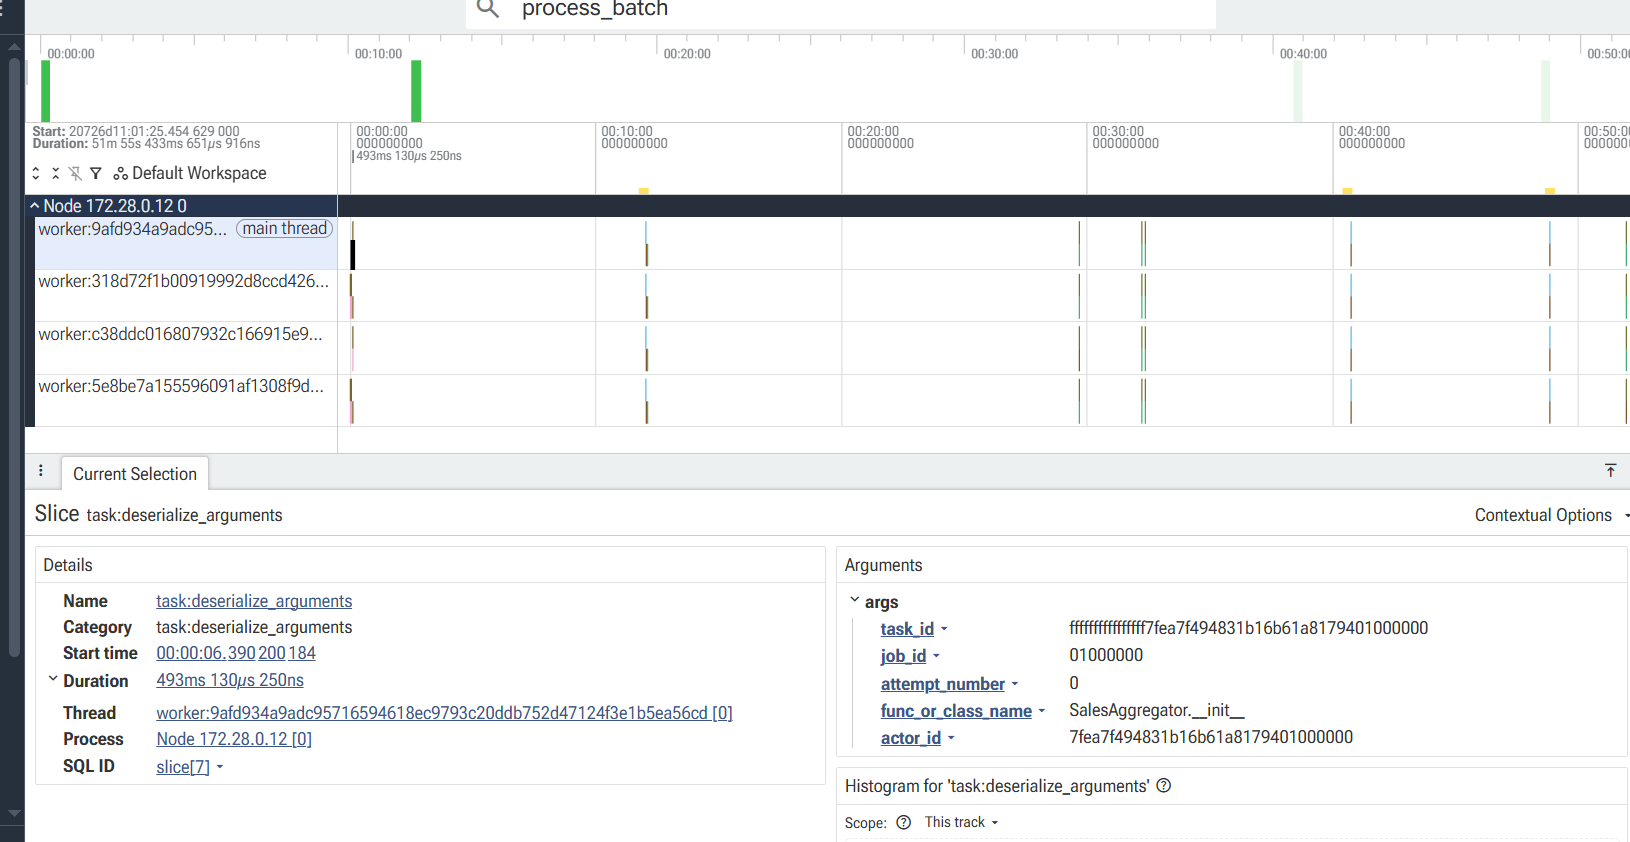

In [ ]:
print_actor_statistics(statistics)

Actor   Batches   Rows        Quantity       Revenue        Products    Countries   
------------------------------------------------------------------------------------
1       3         131,220     1,326,814      2,597,391.81   3177        32          
2       3         131,220     1,401,450      2,646,570.20   3241        32          
3       3         131,219     1,522,082      2,777,777.44   3145        32          
4       3         131,219     1,322,074      2,620,371.35   3106        26          


На завершальному етапі агрегуємо статистику, отриману від усіх Actor, в єдиний підсумковий результат. Сумуємо загальну кількість оброблених рядків, проданих товарів і виручку, а також визначаємо кількість Actor та оброблених ними батчів.


In [ ]:
def print_final_summary(statistics):
    total_rows = sum(stat["rows"] for stat in statistics)
    total_quantity = sum(stat["quantity"] for stat in statistics)
    total_revenue = sum(stat["revenue"] for stat in statistics)
    total_products = len(set(stat["unique_products"] for stat in statistics))
    total_countries = len(set(stat["unique_countries"] for stat in statistics))
    print(f"Actors: {len(statistics)}")
    print(f"Batches per Actor: {statistics[0]['batches_processed']}")
    print(f"Total processed rows: {total_rows:,}")
    print(f"Total quantity: {total_quantity:,.0f}")
    print(f"Total revenue: £{total_revenue:,.2f}")

In [ ]:
statistics = get_actor_statistics(actors)
print_final_summary(statistics)

Actors: 4
Batches per Actor: 3
Total processed rows: 524,878
Total quantity: 5,572,420
Total revenue: £10,642,110.80


У результаті розподілених обчислень дані були розподілені між 4 Actor і оброблені по 3 батчі кожним. Після завершення обробки статистика всіх Actor була агрегована в єдиний підсумок, що підтверджує коректне накопичення стану та обробку всіх частин датасету. Загальні показники узгоджуються з результатами роботи окремих Actor, тому реалізацію можна вважати коректною.


# 3. Дослідити організацію поведінки розподіленої системи на основі моделі Agent.

**Опис моделі та її особливості**
Модель Agent (агентна модель) зосереджена на дослідженні та організації автономної поведінки розподілених сутностей. На відміну від пасивних задач чи статичних акторів, агент є цілеспрямованим об'єктом, який здатний самостійно сприймати зовнішнє середовище, обробляти інформацію та приймати рішення у режимі реального часу. В основі моделі лежить класичний цикл взаємодії Perception-Deliberation-Action (сприйняття — аналіз — дія), що дозволяє системі адаптуватися до змінних умов і виконувати складні розподілені сценарії поведінки.

Основною відмінністю моделі Agent є сукупність її ключових поведінкових властивостей, що забезпечують високий рівень самоорганізації.

Агенти володіють автономністю, тобто здатні самостійно приймати рішення та обирати подальші дії без постійного прямого керування ззовні. Вони проявляють реактивність, оперативно реагуючи на зміни, що відбуваються в навколишньому середовищі. По-третє, агенти  не лише пасивно реагують на події, а й цілеспрямовано виконують кроки для досягнення власних завдань. Важливим аспектом є соціальність, яка дозволяє агентам ефективно комунікувати та взаємодіяти з іншими аналогічними сутностями в межах розподіленої системи.

**Основні сутності та механізми**
Агент (Agent) є автономною програмною сутністю, яка має власні цілі, внутрішній стан і правила прийняття рішень. Він взаємодіє із середовищем (Environment), яким може бути розподілена система, стан кластера або набір транзакцій. Для взаємодії використовуються сенсори та актори (Sensors & Actuators), які забезпечують отримання інформації із середовища та виконання необхідних дій.

Робота агента відбувається за циклом «сприйняття – аналіз – рішення – дія». Після отримання нового блоку даних агент аналізує його характеристики та самостійно визначає подальшу дію. Якщо блок відповідає очікуваним характеристикам, виконується ACCEPT і його результати додаються до накопиченого стану. У разі виявлення аномалії агент може виконати RECOMPUTE та ініціювати повторну обробку, а якщо проблема зберігається — виконати REJECT і зафіксувати проблему через ALERT.

**Реалізація в Ray**
У фреймворку Ray модель Agent природно реалізується на базі розширених класів-акторів (@ray.remote), де кожен екземпляр актора виконує роль автономного агента з власним неперервним циклом виконання (наприклад, через фоновий потік чи метод опитування середовища). Окрім цього, для складних задач поведінкового моделювання та навчання екосистема Ray надає спеціалізовані інструменти, такі як Ray RLlib.

In [ ]:
@ray.remote
class DataAgent:
    def __init__(self):
        self.processed = 0
        self.rejected = 0

    def process(self, data):
        if data["value"] >= 0:
            self.processed += 1
            return "ACCEPT"
        else:
            self.rejected += 1
            return "REJECT"

agent = DataAgent.remote()

result = ray.get(agent.process.remote({"value": 10}))
print(result)

У цьому прикладі клас DataAgent реалізує автономного агента, а його метод process() відповідає за аналіз отриманих даних і вибір дії. Агент самостійно визначає, прийняти чи відхилити блок, а змінні processed і rejected зберігають його внутрішній стан між викликами. Декоратор @ray.remote дозволяє виконувати агента як розподілений об'єкт у Ray.

**Інші засоби реалізації**
Окрім використання Ray, для розробки класичних агентних систем існує низка спеціалізованих платформ, таких як Java-платформа JADE зі стандартами FIPA, Python-фреймворк SPADE, а також системи Jason і JaCaMo для реалізації архітектури BDI. Для завдань імітаційного моделювання та аналізу поведінки масових сутностей широко застосовуються середовища Mesa, NetLogo, AnyLogic та GAMA. Водночас сучасний етап розвитку технологій активно використовує передові фреймворки на базі великих мовних моделей (LLM), зокрема LangGraph, AutoGen і CrewAI.


# Реалізація власної задачі

Підготуємо новий кластер для зручності

In [ ]:
os.environ["RAY_DASHBOARD_SUBPROCESS_MODULE_WAIT_READY_TIMEOUT"] = "300"

if ray.is_initialized():
    ray.shutdown()

try:
    ray.init(include_dashboard=True, log_to_driver=False)
    DASHBOARD_OK = True
except Exception as error:
    print("Dashboard did not start, Ray is started without it")
    ray.shutdown()
    ray.init(include_dashboard=False, log_to_driver=False)
    DASHBOARD_OK = False

NUM_CPUS = int(ray.cluster_resources()["CPU"])

print(f"Ray version: {ray.__version__}")
print(f"Available CPUs: {NUM_CPUS}")
print(f"Dashboard: {'on' if DASHBOARD_OK else 'off'}")
try:
    from google.colab import output
    output.serve_kernel_port_as_window(8265, path="/")
except ImportError:
    print("Open the Ray Dashboard at http://127.0.0.1:8265")

2026-09-30 17:08:25,209	INFO worker.py:2015 -- Started a local Ray instance. View the dashboard at http://127.0.0.1:8265 


Ray version: 2.58.0
Available CPUs: 2
Dashboard: on
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

Для експерименту ми використовуємо набір даних Online Retail, на основі якого аналізуємо поведінку клієнтів. Для кожного клієнта ми формуємо RFM-показники:

Recency — давність останньої покупки;
Frequency — кількість унікальних замовлень;
Monetary — загальна сума покупок.
На основі цих показників ми створюємо Customer Retention Agent, який реалізується як Ray Actor. При цьому Actor використовується як механізм виконання та збереження стану, а агентна поведінка реалізується через автономний цикл прийняття рішень.

**Етап підготовки даних**
Для кожного клієнта показник Recency визначається як кількість днів від дати його останньої покупки до наступного дня після останньої дати в датасеті. Frequency — це кількість унікальних номерів замовлень (InvoiceNo), зроблених клієнтом. Monetary — це загальна сума витрат клієнта, яка розраховується як сума значень TotalPrice за всі його покупки.


In [ ]:
def prepare_customer_data(df):
    data = df.dropna(subset=["CustomerID"]).copy()
    reference_date = data["InvoiceDate"].max() + pd.Timedelta(days=1)
    customer_data = data.groupby("CustomerID").agg(LastPurchase=("InvoiceDate", "max"), Frequency=("InvoiceNo", "nunique"), Monetary=("TotalPrice", "sum")).reset_index()
    customer_data["Recency"] = (reference_date - customer_data["LastPurchase"]).dt.days
    return customer_data[["CustomerID", "Recency", "Frequency", "Monetary"]]

In [ ]:
customer_data = prepare_customer_data(clean_dataframe)
print(customer_data.head())

   CustomerID  Recency  Frequency  Monetary
0     12346.0      326          1  77183.60
1     12347.0        2          7   4310.00
2     12348.0       75          4   1797.24
3     12349.0       19          1   1757.55
4     12350.0      310          1    334.40


Усередині агента реалізовано самостійне обчислення RiskScore, на основі якого агент визначає ризик втрати клієнта та обирає retention-дію. Для цього використовуються percentile ranks — відносні ранги значень Recency, Frequency та Monetary серед усіх клієнтів.

Ранки обчислюються так:

RecencyRank — визначає відносне положення клієнта за Recency серед усіх клієнтів. Чим більший Recency, тим вищий ранг, тобто клієнт довше не здійснював покупку і має більший ризик.
FrequencyRank — визначає відносне положення клієнта за кількістю покупок. Чим більше покупок здійснив клієнт, тим вищий ранг, що зменшує його ризик.
MonetaryRank — визначає відносне положення клієнта за загальною сумою витрат. Вища сума витрат відповідає вищому рангу та зменшує ризик.

Після цього агент розраховує RiskScore за формулою:

RiskScore = 0.5 × RecencyRank + 0.3 × (1 − FrequencyRank) + 0.2 × (1 − MonetaryRank)

Таким чином, більша давність покупки збільшує ризик, а більша частота покупок і сума витрат його зменшують. Після отримання RiskScore агент самостійно визначає рівень ризику через поділ значень на три групи: LOW_RISK, MEDIUM_RISK та HIGH_RISK.

Залежно від визначеного ризику агент приймає відповідне рішення:

LOW_RISK → NO_ACTION;
MEDIUM_RISK → SEND_OFFER;
HIGH_RISK → PRIORITY_OFFER.

In [ ]:
@ray.remote
class CustomerRetentionAgent:
    def __init__(self, customers):
        self.customers = customers.copy()
        self.observations = 0
        self.decisions = 0
        self.actions = 0
        self.risk_counts = {"LOW_RISK": 0, "MEDIUM_RISK": 0, "HIGH_RISK": 0}
        self.action_counts = {"NO_ACTION": 0, "SEND_OFFER": 0, "PRIORITY_OFFER": 0}
        self.processed_customers = []

    def calculate_risk_scores(self):
        data = self.customers.copy()
        data["RecencyRank"] = data["Recency"].rank(pct=True)
        data["FrequencyRank"] = data["Frequency"].rank(pct=True)
        data["MonetaryRank"] = data["Monetary"].rank(pct=True)
        data["RiskScore"] = 0.5 * data["RecencyRank"] + 0.3 * (1 - data["FrequencyRank"]) + 0.2 * (1 - data["MonetaryRank"])
        data["Risk"] = pd.qcut(data["RiskScore"], q=[0, 0.5, 0.8, 1], labels=["LOW_RISK", "MEDIUM_RISK", "HIGH_RISK"])
        return data

    def observe(self, customer_id):
        data = self.calculate_risk_scores()
        customer = data[data["CustomerID"] == customer_id].iloc[0]
        self.observations += 1
        return {"CustomerID": customer["CustomerID"], "Recency": customer["Recency"], "Frequency": customer["Frequency"], "Monetary": customer["Monetary"], "RiskScore": customer["RiskScore"], "Risk": customer["Risk"]}

    def decide(self, observation):
        actions = {"LOW_RISK": "NO_ACTION", "MEDIUM_RISK": "SEND_OFFER", "HIGH_RISK": "PRIORITY_OFFER"}
        risk = str(observation["Risk"])
        action = actions[risk]
        self.decisions += 1
        self.risk_counts[risk] += 1
        return {"CustomerID": observation["CustomerID"], "RiskScore": observation["RiskScore"], "Risk": risk, "Action": action}

    def act(self, decision):
        self.actions += 1
        self.action_counts[decision["Action"]] += 1
        self.processed_customers.append(decision["CustomerID"])
        return decision

    def process_customer(self, customer_id):
        observation = self.observe(customer_id)
        decision = self.decide(observation)
        return self.act(decision)

    def process_batch(self, customer_ids):
        return [self.process_customer(customer_id) for customer_id in customer_ids]

    def get_statistics(self):
        return {"observations": self.observations, "decisions": self.decisions, "actions": self.actions, "risk_counts": self.risk_counts, "action_counts": self.action_counts, "processed_customers": len(self.processed_customers)}

In [ ]:
agent = CustomerRetentionAgent.remote(customer_data)
customer_ids = customer_data["CustomerID"].tolist()
customer_batches = np.array_split(customer_ids, 4)

In [ ]:
batch_results = []
for batch in customer_batches:
    result = ray.get(agent.process_batch.remote(batch))
    batch_results.extend(result)

Observations: 4,338
Decisions: 4,338
Actions: 4,338
Risk distribution:
{'LOW_RISK': 2169, 'MEDIUM_RISK': 1301, 'HIGH_RISK': 868}
Action distribution:
{'NO_ACTION': 2169, 'SEND_OFFER': 1301, 'PRIORITY_OFFER': 868}


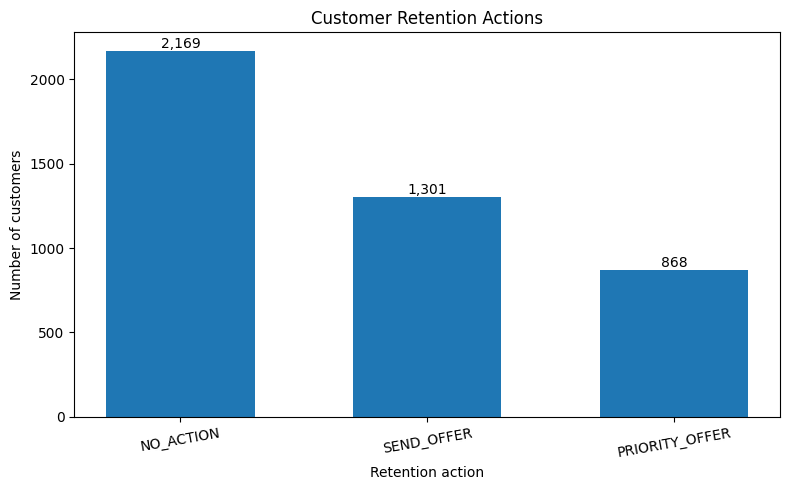

In [ ]:
import matplotlib.pyplot as plt

statistics = ray.get(agent.get_statistics.remote())

print(f"Observations: {statistics['observations']:,}")
print(f"Decisions: {statistics['decisions']:,}")
print(f"Actions: {statistics['actions']:,}")

print("Risk distribution:")
print(statistics["risk_counts"])

print("Action distribution:")
print(statistics["action_counts"])

# Гістограма розподілу дій агента
action_counts = statistics["action_counts"]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    action_counts.keys(),
    action_counts.values(),
    width=0.6
)

plt.xlabel("Retention action")
plt.ylabel("Number of customers")
plt.title("Customer Retention Actions")

# Значення над стовпчиками
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

За результатами гістограми видно, що агент обробив 4 338 клієнтів, для кожного з яких було виконано спостереження, прийняття рішення та відповідну дію. Найбільше клієнтів, 2 169 (50%), отримали дію NO_ACTION, що відповідає низькому рівню ризику. Для 1 301 клієнта (30%) агент визначив SEND_OFFER, а для 868 клієнтів (20%) — PRIORITY_OFFER. Розподіл дій повністю відповідає розподілу рівнів ризику та демонструє послідовну роботу механізму прийняття рішень агента.


In [ ]:
ray.shutdown()

# 4. Додатково. Дослідити модель багатоагентної взаємодії (Multi-Agent).

**Опис моделі та її особливості**
Модель Multi-Agent (багатоагентна система, МАС) описує організацію складних розподілених систем, що складаються з кількох автономних агентів, які діють у спільному середовищі. На відміну від одноагентних систем, тут фокус зміщується на комунікацію, координацію та колективне досягнення локальних чи глобальних цілей. Агенти можуть діяти як кооперативно (допомагаючи один одному), так і конкурентно (змагаючись за обмежені ресурси системи), що дозволяє моделювати реальні соціально-економічні чи технічні процеси.

**Основні сутності та механізми взаємодії**

У багатоагентній системі вирішальне значення мають не лише індивідуальні характеристики окремих агентів, а й способи їхньої комунікації, обміну інформацією та координації колективної поведінки. Будь-яка подібна система базується на чіткому наборі сутностей та механізмів:
Agents (Агенти): автономні програмні або фізичні сутності, кожна з яких має власний стан, локальну інформацію та цілі.

Середовище (Environment): загальний простір, у якому функціонують агенти, виконують дії та фіксують зміни.

Топологія зв'язків (Topology): структура комунікації, яка визначає, хто з ким може безпосередньо зв'язуватися (наприклад, повнозв'язкова мережа «усі з усіма», кільцева топологія або локальні сусіди).

Повідомлення (Messages): одиниці інформації, якими агенти обмінюються для передачі даних чи запитів.

Протоколи взаємодії (Protocols): формалізовані правила та регламенти обміну повідомленнями.

Організація (Organization): ієрархія, ролі, розподіл обов'язків і групові правила, що регулюють спільну діяльність.


**Реалізація в Ray та інших засобах**

У Ray немає окремого примітиву для Multi-Agent Systems, тому агенти реалізуються на основі Ray Actors. Вони взаємодіють напряму через отримані ActorHandle та виклики методів на кшталт peer.method.remote().

Оскільки за замовчуванням актори виконують методи послідовно, для забезпечення конкурентності використовуються багатопотокові актори (threaded Actors) із параметром max_concurrency, де спільний стан захищено за допомогою threading.Lock. Зокрема, кожен агент  обмінюється gossip-повідомленнями асинхронно через `.remote()` без негайного очікування через `ray.get()`, що дозволяє їм продовжувати роботу без взаємних блокувань.

**Реалізація на інших засобах**

Окрім Ray, для реалізації багатоагентних взаємодій широко застосовуються класична платформа JADE (на базі стандартів FIPA), імітаційне середовище AnyLogic, а також сучасні фреймворки оркестрації агентів, такі як AutoGen або CrewAI.

**Проведення власного експерименту**


Для кращої демонстративності взаємодії в мультиагентному середовищі об'єднаємо завдання 4 та 5, що полягає у інтелектуалізації розподілених обчислень. Інтелектуалізація реалізується шляхом інтеграції ML-моделі прогнозування продажів у багатоагентну систему.

# 5. Додатково. Дослідити інтелектуалізовану організацію розподілених обчислень.

**Підхід до інтелектуалізації**

Інтелектуалізація розподілених обчислень реалізується шляхом використання системи спеціалізованих агентів, кожен з яких відповідає за окремий етап обробки та аналізу даних. У запропонованій системі використовуються DataAgent, FeatureAgent, ForecastAgent, AnalysisAgent та DecisionAgent. Такий підхід дозволяє поєднати паралельне виконання обчислень у Ray з автономним аналізом отриманих результатів і прийняттям рішень.

**Основні механізми інтелектуальної обробки та прийняття рішень**

Основними механізмами є підготовка та розподілення даних, формування ознак, прогнозування за допомогою моделі машинного навчання, інтерпретація прогнозу та прийняття рішення на основі отриманих результатів. DataAgent готує історичні дані про продажі, FeatureAgent формує часові та статистичні характеристики, ForecastAgent прогнозує майбутню виручку, AnalysisAgent визначає стан продажів, а DecisionAgent агрегує результати та формує кінцеве рішення.

**Застосування в розподіленій системі**

У середовищі Ray кожен агент може функціонувати як окремий розподілений об'єкт, а його методи виконуються асинхронно за допомогою .remote(). Історичні дані можуть розподілятися на блоки та оброблятися паралельно різними агентами, після чого результати передаються наступним етапам системи. Наприклад, FeatureAgent паралельно розраховує характеристики окремих частин даних, ForecastAgent виконує прогнозування, а AnalysisAgent та DecisionAgent використовують отримані результати для подальшого аналізу та прийняття рішення.

**Власний експеримент**

У межах експерименту використано набір даних Online Retail, на основі якого DataAgent формує щоденний часовий ряд виручки. Далі розраховуються часові ознаки, лагові значення lag_1, lag_7 та ковзні середні rolling_mean_7, rolling_mean_30, після чого ForecastAgent за допомогою RandomForestRegressor прогнозує майбутню виручку. AnalysisAgent порівнює прогноз із попереднім рівнем продажів і визначає стан як спад, стабільний стан або зростання, а DecisionAgent на основі цього формує кінцеву дію. Експеримент демонструє, що розподілена система може виконувати не лише паралельну обробку даних, а й автоматично аналізувати результати та приймати рішення на їх основі.

In [ ]:
!pip install -q -U crewai ray scikit-learn

In [ ]:
import numpy as np
import pandas as pd
import sklearn

print(np.__version__)
print(pd.__version__)
print(sklearn.__version__)

2.2.6
2.2.3
1.9.1


In [ ]:
import os
import time
import numpy as np
import pandas as pd
import ray
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from crewai import Agent, Task, Crew, Process, LLM

In [ ]:
if not ray.is_initialized(): ray.init(num_cpus=4)

2026-09-30 18:15:29,245	INFO worker.py:2015 -- Started a local Ray instance. View the dashboard at http://127.0.0.1:8265 


**Виконуємо підготовку даних**
На цьому етапі ми перетворюємо початкові дані про окремі замовлення на часовий ряд щоденної виручки. Для кожної дати обчислюється загальна виручка шляхом сумування TotalPrice, після чого формується окрема таблиця з двома основними показниками: датою та виручкою. Ці дані є основою для подальшої роботи агентної системи, оскільки саме на щоденній виручці ForecastAgent буде будувати прогноз на наступні 7 днів. Результат зберігається у daily_sales, щоб його могли використовувати наступні агенти.

In [ ]:
def calculate_daily_sales(df):
    daily_sales = df.groupby(df["InvoiceDate"].dt.date)["TotalPrice"].sum().reset_index()
    daily_sales.columns = ["Date", "Revenue"]
    daily_sales["Date"] = pd.to_datetime(daily_sales["Date"])
    return daily_sales

daily_sales = calculate_daily_sales(clean_dataframe)

In [ ]:
daily_sales.head()

,Date,Revenue
0,2010-12-01,58776.79
1,2010-12-02,47629.42
2,2010-12-03,46898.63
3,2010-12-05,31364.63
4,2010-12-06,54624.15


Тут ми переносимо підготовку щоденних продажів усередину окремого Ray-агента DataAgent. Агент отримує очищені транзакційні дані, перетворює дату операції на денний формат і групує всі продажі за датами. Для кожного дня одночасно розраховуються виручка, кількість унікальних замовлень та загальна кількість проданих одиниць.

In [ ]:
@ray.remote
class DataAgent:
    def prepare_sales_data(self, df):
        data = df.copy()
        data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
        data["Date"] = data["InvoiceDate"].dt.floor("D")
        daily_sales = data.groupby("Date").agg(Revenue=("TotalPrice", "sum"), Orders=("InvoiceNo", "nunique"), Quantity=("Quantity", "sum")).reset_index()
        daily_sales = daily_sales.sort_values("Date").reset_index(drop=True)
        return daily_sales

На цьому етапі FeatureAgent перетворює історичні дані про щоденну виручку на ознаки, необхідні для прогнозування майбутніх продажів. Він створює лагові ознаки — виручку за попередній день, 7 і 14 днів тому — а також ковзні середні за 7 і 30 днів, щоб модель могла враховувати короткострокову та довгострокову динаміку. Додатково формуються календарні ознаки: день тижня та місяць. Кілька таких FeatureAgent у нашій системі працюють розподілено над окремими частинами даних, після чого їхні результати використовуються ForecastAgent для навчання моделі прогнозування.

In [ ]:
@ray.remote
class FeatureAgent:
    def prepare_features(self, data):
        data = data.copy()
        data["lag_1"] = data["Revenue"].shift(1)
        data["lag_7"] = data["Revenue"].shift(7)
        data["lag_14"] = data["Revenue"].shift(14)
        data["rolling_7"] = data["Revenue"].rolling(7).mean()
        data["rolling_30"] = data["Revenue"].rolling(30).mean()
        data["day_of_week"] = data["Date"].dt.dayofweek
        data["month"] = data["Date"].dt.month
        return data.dropna().reset_index(drop=True)

Тут FeatureCoordinatorAgent відповідає за організацію розподіленої роботи кількох FeatureAgent. Він розділяє підготовлені дані на кілька частин відповідно до кількості агентів і одночасно передає кожну частину окремому FeatureAgent через Ray. Після завершення паралельної обробки результати всіх агентів збираються та об'єднуються в одну таблицю, відсортовану за датою.

In [ ]:
@ray.remote
class FeatureCoordinatorAgent:
    def process(self, data, agents):
        chunks = np.array_split(data, len(agents))
        refs = [agents[i].prepare_features.remote(chunks[i]) for i in range(len(agents))]
        results = ray.get(refs)
        return pd.concat(results).sort_values("Date").reset_index(drop=True)

На цьому етапі ForecastAgent відповідає за навчання єдиної ML-моделі та прогнозування майбутньої виручки. Він використовує створені попередніми агентами часові ознаки та навчає RandomForestRegressor, залишаючи останні 7 днів для перевірки якості моделі за метрикою MAE. Після оцінювання агент послідовно прогнозує виручку на наступні 7 днів, причому кожен новий прогноз використовується для формування ознак наступного дня. У результаті агент повертає прогнозовані значення виручки, відповідні дати та MAE, які далі передаються AnalysisAgent для визначення очікуваної зміни продажів.

In [ ]:
@ray.remote
class ForecastAgent:
    def train_and_predict(self, data, horizon):
        features = ["lag_1", "lag_7", "lag_14", "rolling_7", "rolling_30", "day_of_week", "month"]
        train_size = len(data) - horizon
        train = data.iloc[:train_size].copy()
        test = data.iloc[train_size:].copy()
        X_train = train[features]
        y_train = train["Revenue"]
        X_test = test[features]
        y_test = test["Revenue"]
        model = RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=1)
        model.fit(X_train, y_train)
        test_predictions = model.predict(X_test)
        mae = mean_absolute_error(y_test, test_predictions)
        future = data.copy()
        future_predictions = []
        future_dates = []
        for _ in range(horizon):
            last_date = future.iloc[-1]["Date"]
            next_date = last_date + pd.Timedelta(days=1)
            row = {"Date": next_date, "lag_1": future.iloc[-1]["Revenue"], "lag_7": future.iloc[-7]["Revenue"], "lag_14": future.iloc[-14]["Revenue"], "rolling_7": future["Revenue"].tail(7).mean(), "rolling_30": future["Revenue"].tail(30).mean(), "day_of_week": next_date.dayofweek, "month": next_date.month}
            prediction = model.predict(pd.DataFrame([row])[features])[0]
            future_predictions.append(float(prediction))
            future_dates.append(next_date)
            future = pd.concat([future, pd.DataFrame([{"Date": next_date, "Revenue": prediction}])], ignore_index=True)
        return {"predictions": future_predictions, "dates": future_dates, "mae": float(mae)}

На цьому етапі AnalysisAgent аналізує результат роботи ForecastAgent та визначає, як зміниться очікувана виручка порівняно з останніми 7 днями історичних продажів. Спочатку агент обчислює сумарну виручку за останні 7 історичних днів, а потім — сумарну прогнозовану виручку за наступні 7 днів. На основі цих двох значень розраховується відносна очікувана зміна виручки.

In [ ]:
@ray.remote
class AnalysisAgent:
    def analyze(self, historical_data, forecast):
        historical_revenue = historical_data["Revenue"].tail(7).sum()
        forecast_revenue = sum(forecast["predictions"])
        expected_change = (forecast_revenue - historical_revenue) / historical_revenue
        return {"historical_revenue": float(historical_revenue), "forecast_revenue": float(forecast_revenue), "expected_change": float(expected_change), "predictions": forecast["predictions"], "dates": forecast["dates"], "mae": forecast["mae"]}

DecisionAgent перетворює числовий результат аналізу на зрозумілий стан продажів. Агент отримує від AnalysisAgent очікувану зміну виручки та порівнює її з визначеними порогами: понад 5% означає зростання, менше −5% — спад, а значення між ними — стабільний стан. Таким чином, агент виконує фінальний етап прийняття рішення в нашій системі на основі результату прогнозування. Разом зі станом він повертає всі основні показники прогнозу, щоб їх можна було використати для підсумкового виведення результатів.

In [ ]:
@ray.remote
class DecisionAgent:
    def determine_state(self, analysis):
        change = analysis["expected_change"]
        if change > 0.05:
            state = "Growth"
        elif change < -0.05:
            state = "Decline"
        else:
            state = "Stable"
        return {"state": state, "historical_revenue": analysis["historical_revenue"], "forecast_revenue": analysis["forecast_revenue"], "expected_change": analysis["expected_change"], "predictions": analysis["predictions"], "dates": analysis["dates"], "mae": analysis["mae"]}

CoordinatorAgent є центральним агентом, який організовує повний процес роботи всієї багатоагентної системи. Він створює спеціалізованих агентів, передає між ними результати та визначає послідовність етапів: підготовка даних → розподілена генерація ознак → прогнозування → аналіз → прийняття рішення. Сам CoordinatorAgent не виконує ML-обчислення, а координує взаємодію між іншими агентами через Ray. Наприкінці він збирає результати всіх етапів в один структурований словник, який використовується для подальшого виведення та аналізу роботи системи.

In [ ]:
@ray.remote
class CoordinatorAgent:
    def run(self, df, num_feature_agents=4, horizon=7):
        start_time = time.perf_counter()
        data_agent = DataAgent.remote()
        feature_agents = [FeatureAgent.remote() for _ in range(num_feature_agents)]
        feature_coordinator = FeatureCoordinatorAgent.remote()
        forecast_agent = ForecastAgent.remote()
        analysis_agent = AnalysisAgent.remote()
        decision_agent = DecisionAgent.remote()
        data_ref = ray.put(df)
        daily_sales_ref = data_agent.prepare_sales_data.remote(data_ref)
        features_ref = feature_coordinator.process.remote(daily_sales_ref, feature_agents)
        features = ray.get(features_ref)
        forecast_ref = forecast_agent.train_and_predict.remote(features, horizon)
        forecast = ray.get(forecast_ref)
        daily_sales = ray.get(daily_sales_ref)
        analysis_ref = analysis_agent.analyze.remote(daily_sales, forecast)
        decision_ref = decision_agent.determine_state.remote(analysis_ref)
        decision = ray.get(decision_ref)
        execution_time = time.perf_counter() - start_time
        agent_status = {
            "DataAgent": "completed",
            "FeatureAgents": num_feature_agents,
            "ForecastAgent": "completed",
            "AnalysisAgent": "completed",
            "DecisionAgent": "completed"
        }

        result = {
            "system": "Distributed Multi-Agent Sales Forecasting System",
            "agents": agent_status,
            "input_rows": len(df),
            "historical_days": len(daily_sales),
            "feature_rows": len(features),
            "forecast_horizon": horizon,
            "historical_revenue": decision["historical_revenue"],
            "forecast_revenue": decision["forecast_revenue"],
            "expected_change": decision["expected_change"],
            "state": decision["state"],
            "mae": decision["mae"],
            "predictions": decision["predictions"],
            "dates": decision["dates"],
            "execution_time": execution_time
        }


In [ ]:
coordinator = CoordinatorAgent.remote()
result_ref = coordinator.run.remote(clean_dataframe, num_feature_agents=4, horizon=7)
result = ray.get(result_ref)

(FeatureCoordinatorAgent pid=230057) /usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
(FeatureCoordinatorAgent pid=230057)   return bound(*args, **kwds)


In [ ]:
print("=" * 70)
print("DISTRIBUTED MULTI-AGENT SALES FORECASTING SYSTEM")
print("=" * 70)
print("Input transactions:", result["input_rows"])
print("Historical days:", result["historical_days"])
print("Feature records:", result["feature_rows"])
print("Forecast horizon:", result["forecast_horizon"], "days")
print("Execution time:", round(result["execution_time"], 3), "seconds")

DISTRIBUTED MULTI-AGENT SALES FORECASTING SYSTEM
Input transactions: 524878
Historical days: 305
Feature records: 189
Forecast horizon: 7 days
Execution time: 35.956 seconds


In [ ]:
forecast_df = pd.DataFrame({"Date": pd.to_datetime(result["dates"]), "ForecastRevenue": result["predictions"]})
forecast_df["ForecastRevenue"] = forecast_df["ForecastRevenue"].round(2)
forecast_df

,Date,ForecastRevenue
0,2011-12-10,93236.25
1,2011-12-11,75101.23
2,2011-12-12,95766.52
3,2011-12-13,95695.11
4,2011-12-14,95956.87
5,2011-12-15,93182.92
6,2011-12-16,91806.42


In [ ]:
print()
print("=" * 70)
print("FINAL SALES STATE")
print("=" * 70)
print("State:", result["state"])
print("Expected revenue change:", round(result["expected_change"] * 100, 2), "%")
print("Forecast revenue for next 7 days:", round(result["forecast_revenue"], 2))
print("=" * 70)


FINAL SALES STATE
State: Growth
Expected revenue change: 9.39 %
Forecast revenue for next 7 days: 640745.32


Як можна побачити було оброблено 524 878 транзакцій і сформувано дані за 305 історичними днями, після чого прогнозувала виручку на наступні 7 днів. Прогнозована виручка становить 640 745,32, що на 9,39% більше за виручку останніх 7 історичних днів (585 721,70), тому DecisionAgent визначить стан продажів як Growth. Час виконання всієї багатоагентної системи склав 35,956 с. Прогнозовані значення демонструють відносно стабільний рівень щоденної виручки протягом прогнозного тижня, переважно в межах приблизно 91–96 тис.

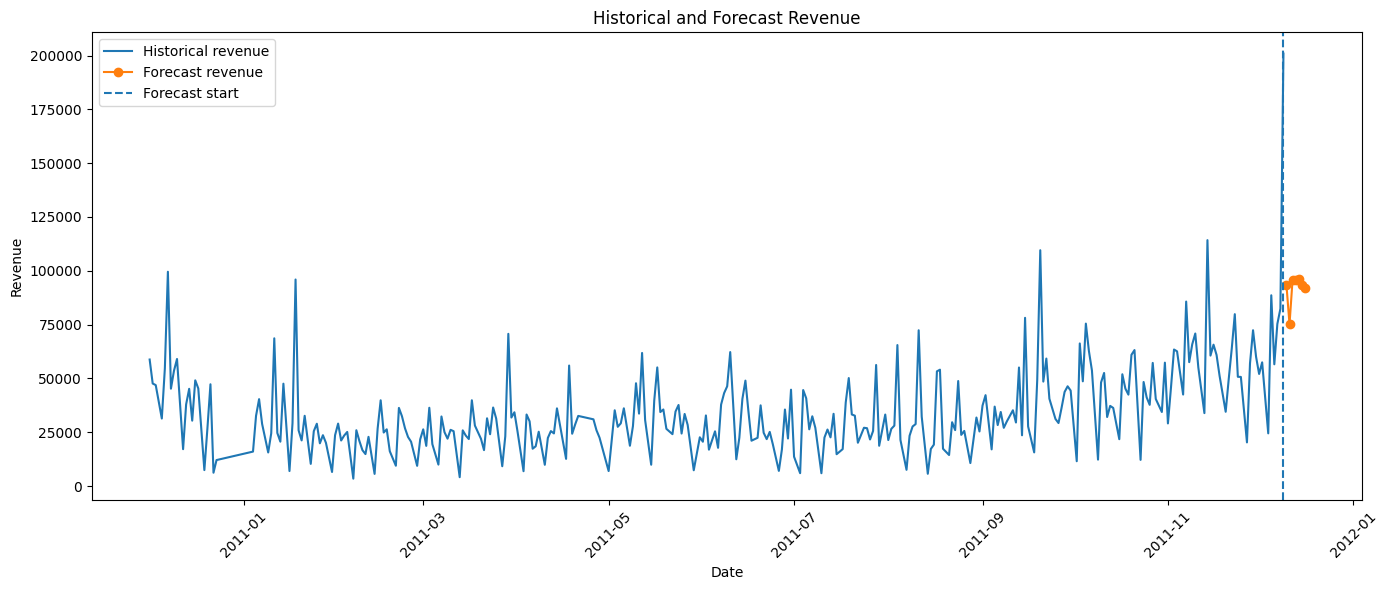

In [ ]:
import matplotlib.pyplot as plt

historical_plot = clean_dataframe.copy()
historical_plot["InvoiceDate"] = pd.to_datetime(historical_plot["InvoiceDate"])
historical_plot["Date"] = historical_plot["InvoiceDate"].dt.floor("D")
historical_plot = historical_plot.groupby("Date")["TotalPrice"].sum().reset_index()

plt.figure(figsize=(14, 6))

plt.plot(
    historical_plot["Date"],
    historical_plot["TotalPrice"],
    label="Historical revenue"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["ForecastRevenue"],
    marker="o",
    label="Forecast revenue"
)

plt.axvline(
    historical_plot["Date"].max(),
    linestyle="--",
    label="Forecast start"
)

plt.xlabel("Date")
plt.ylabel("Revenue")
plt.title("Historical and Forecast Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()